### 🎯 O que você vai ser capaz de fazer ao final da aula
1. Explicar por que **estatística vem antes do Machine Learning** (e não depois).
2. Reconhecer **viés de amostragem** e saber por que usamos `stratify=y`.
3. Identificar o formato de uma distribuição e **corrigi-la** com `np.log1p()`.
4. Usar **Score Z** e a **Curva Normal** para calcular probabilidades (e entender o `StandardScaler`).
5. Aplicar **Qui-Quadrado** e **Teste t** como "detectores de mentira" para **selecionar features**.
6. Detectar **variáveis clones** (multicolinearidade) e **vazamento de dados** (*data leakage*) com correlação.
7. Ver, com números reais, a estatística **aumentando a acurácia** de uma Regressão Logística, comparando com um **baseline cego** feito logo no início da aula.


### 🔁 O pipeline que vamos construir

```mermaid
flowchart LR
    A["📦 Dados brutos<br/>(Titanic)"] --> B["🩻 Raio-X estatístico<br/>(módulos 1 a 5)"]
    B --> C["🧹 Limpeza e engenharia de features<br/>(módulos 2, 3, 4 e 5)"]
    C --> D["🤖 Modelo<br/>(módulo 6)"]
    D --> E["📊 Avaliação"]
```

**Nosso problema:** prever se um passageiro do Titanic **sobreviveu** (`survived = 1`) ou **não** (`survived = 0`) a partir de suas características. Isso é um problema de **classificação binária**.


### Importação das Bibliotecas

In [29]:
# Bibliotecas essenciais
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Configurações visuais e de reprodutibilidade
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

SEED = 42            # "semente" aleatória: garante que todos vejam os mesmos resultados
np.random.seed(SEED)

### 🚢 Passo 2 — Carregando o dataset do Titanic

In [30]:
df = sns.load_dataset("titanic")


<img src="exemplo-regr-log.png" alt="regressao-logistica" width="90%"/>

### Extratificação das Amostras

In [31]:


FEATURES = ["pclass", "age", "sibsp", "parch", "fare"]
TARGET = "survived"

treino_base, teste_base = train_test_split(
    df, test_size=0.2, stratify=df[TARGET], random_state=SEED
)


X_treino = treino_base[FEATURES].fillna(0)
y_treino = treino_base[TARGET]

X_teste = teste_base[FEATURES].fillna(0)
y_teste = teste_base[TARGET]

### Treino e Teste

In [32]:
# 2. Treino
modelo_base = LogisticRegression(max_iter=1000)
modelo_base.fit(X_treino, y_treino)

# 3. Teste
pred_base = modelo_base.predict(X_teste)
acuracia_teste = modelo_base.score(X_teste, y_teste)

In [33]:
acuracia_teste

0.664804469273743

### 🔍 Olhando as predições de perto

Uma acurácia solta esconde detalhes. Vamos ver **passageiros concretos** e a matriz de confusão do modelo cego.

In [34]:
amostra = teste_base.sample(8, random_state=3)[["sex", "age", "pclass", "fare", "survived"]].copy()
amostra["previsão"] = modelo_base.predict(X_teste.loc[amostra.index])
amostra["resultado"] = np.where(amostra["survived"] == amostra["previsão"], "acertou", "errou")
amostra

,sex,age,pclass,fare,survived,previsão,resultado
387,female,36.0,2,13.0000,1,0,errou
504,female,16.0,1,86.5000,1,1,acertou
297,female,2.0,1,151.5500,0,1,errou
40,female,40.0,3,9.4750,0,0,acertou
883,male,28.0,2,10.5000,0,0,acertou
752,male,33.0,3,9.5000,0,0,acertou
823,female,27.0,3,12.4750,1,0,errou
146,male,27.0,3,7.7958,1,0,errou


### 📌 Guarde este número!

> O modelo cego acerta pouco mais do que **"chutar que ninguém sobrevive"** e **erra muitos sobreviventes** (veja a coluna *recall* da classe "Sobreviveu" acima). 

Ele **nunca viu** o sexo do passageiro, não sabe que a idade tem buracos, e é enganado pela cauda longa da tarifa.

Agora vem a jornada: ao longo dos módulos 1 a 5 vamos fazer o **raio-X estatístico** dos dados e, no **Módulo 6**, voltar a este ponto para medir **exatamente quanto cada etapa melhorou o resultado**. 🏁

```
 🎲 Teste cego (hoje)  ──►  🩻 EDA + Estatística  ──►  🧹 Preparação  ──►  🧠 Modelo guiado  ──►  📈 Quanto ganhamos?
```

---
## 🍲 MÓDULO 1 — População vs. Amostra (A Metáfora da Panela de Sopa)


Você fez uma **panela enorme de sopa** e quer saber se está salgada. O que você faz?

- ❌ Toma a panela inteira? Não, acabaria com a sopa.
- ✅ Mexe bem e prova **uma colherada**.

| Conceito | Na cozinha | Em Ciência de Dados |
|---|---|---|
| **População** | A panela inteira | **Todos** os casos possíveis (ex.: todos os passageiros que já viajaram) |
| **Amostra** | A colherada | O **subconjunto** que realmente temos para treinar o modelo |
| **Parâmetro** | O sabor real da panela | O valor verdadeiro (geralmente desconhecido) |
| **Estatística** | O sabor da colherada | O valor que calculamos na amostra |

## ⚠️ O perigo: o viés de amostragem

A colherada só representa a panela se você **mexer a sopa antes**. Se pegar só a colherada de cima (onde ficou o sal), vai concluir errado.

> **Viés de amostragem** = quando a amostra **não representa** a população. 
> O modelo aprende uma realidade que não existe e **falha no mundo real**.

**Exemplo clássico:** treinar um modelo de crédito só com clientes de uma única cidade e usá-lo no país inteiro.

## 🎲 Regra de ouro: amostras maiores e bem sorteadas "provam" melhor
Quanto maior a amostra (e mais aleatória), mais a estatística se aproxima do parâmetro. Isso é a **Lei dos Grandes Números**.

---
### 🧪 Experimento 1 — "Provando" a sopa do Titanic

Vamos tratar os **891 passageiros** como nossa "panela inteira" (população) e retirar colheradas de tipos diferentes.

🍲 PANELA INTEIRA (população): taxa de sobrevivência = 38.4% | idade média = 29.7 anos



,n,taxa de sobrevivência,idade média
População (n=891),891.0,0.384,29.699
Amostra pequena (n=10),10.0,0.200,32.333
Amostra grande (n=300),300.0,0.410,30.115
"ENVIESADA (só 1ª classe, n=100)",100.0,0.570,37.028


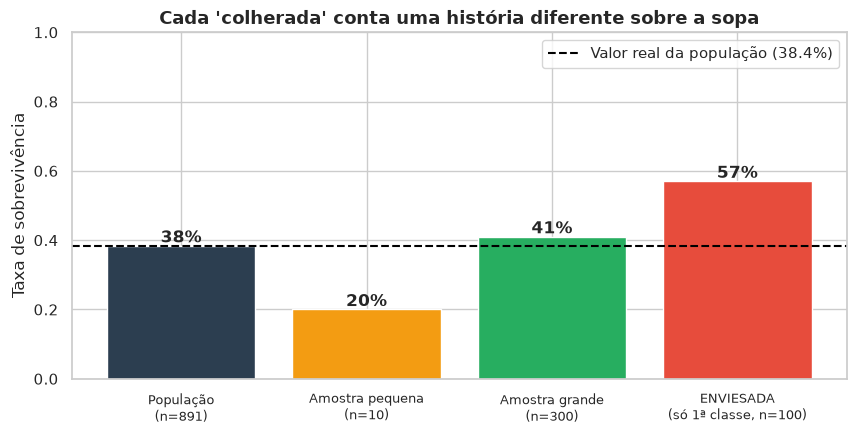

👉 A amostra ENVIESADA (só 1ª classe) superestima a sobrevivência: ela provou só o sal da superfície da panela!


In [35]:
taxa_pop = df["survived"].mean()
idade_pop = df["age"].mean()
print(f"🍲 PANELA INTEIRA (população): taxa de sobrevivência = {taxa_pop:.1%} | idade média = {idade_pop:.1f} anos\n")

amostras = {
    "População\n(n=891)": df,
    "Amostra pequena\n(n=10)": df.sample(n=10, random_state=7),
    "Amostra grande\n(n=300)": df.sample(n=300, random_state=7),
    "ENVIESADA\n(só 1ª classe, n=100)": df[df["pclass"] == 1].sample(n=100, random_state=7),
}

resumo = pd.DataFrame({
    nome.replace("\n", " "): {
        "n": len(a),
        "taxa de sobrevivência": a["survived"].mean(),
        "idade média": a["age"].mean(),
    }
    for nome, a in amostras.items()
}).T
display(resumo.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
cores = ["#2c3e50", "#f39c12", "#27ae60", "#e74c3c"]
barras = ax.bar(range(4), resumo["taxa de sobrevivência"], color=cores)
ax.axhline(taxa_pop, ls="--", color="black", label=f"Valor real da população ({taxa_pop:.1%})")
ax.set_xticks(range(4))
ax.set_xticklabels(list(amostras.keys()), fontsize=9)
ax.set_ylabel("Taxa de sobrevivência")
ax.set_title("Cada 'colherada' conta uma história diferente sobre a sopa")
ax.set_ylim(0, 1)
for b in barras:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.0%}", ha="center", fontweight="bold")
ax.legend()
plt.show()

print("👉 A amostra ENVIESADA (só 1ª classe) superestima a sobrevivência: ela provou só o sal da superfície da panela!")

### 🔁 Experimento 2 — "E se eu repetir a colherada 1.000 vezes?"

Uma única amostra pode ter sorte ou azar. Vamos **repetir o sorteio 1.000 vezes** para cada tamanho de amostra e ver **onde caem** as estimativas.

- Curva **estreita e centrada** no valor real = estimativa confiável ✅
- Curva **larga** = muita variação (amostra pequena) ⚠️
- Curva **estreita mas deslocada** = precisa, porém **errada** (viés!) ❌

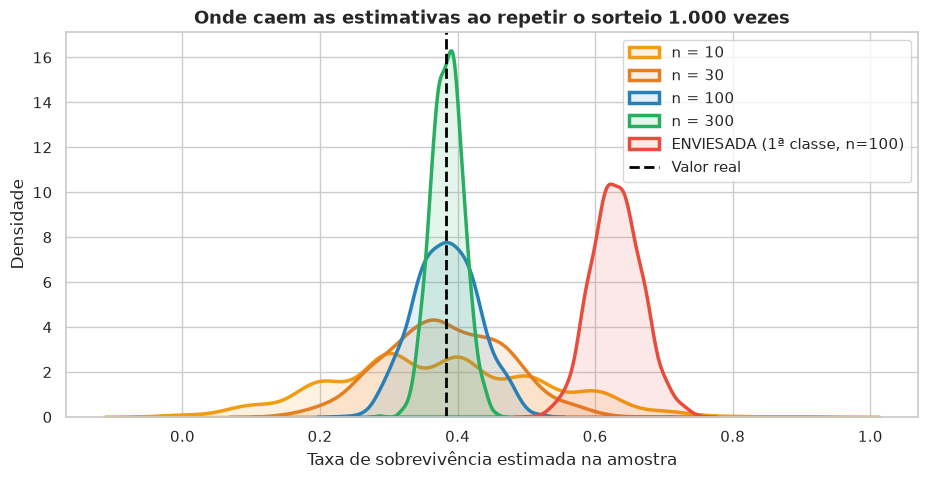

,média das estimativas,variação (desvio padrão)
n = 10,0.375,0.150
n = 30,0.383,0.088
n = 100,0.383,0.047
n = 300,0.384,0.023
"ENVIESADA (1ª classe, n=100)",0.630,0.037


👉 Amostra maior = menos variação. Amostra enviesada = pouca variação, mas está no lugar ERRADO.


In [36]:
rng = np.random.default_rng(SEED)
sobrev_pop = df["survived"].to_numpy()
sobrev_1a = df.loc[df["pclass"] == 1, "survived"].to_numpy()

resultados = {
    f"n = {n}": [rng.choice(sobrev_pop, size=n, replace=False).mean() for _ in range(1000)]
    for n in [10, 30, 100, 300]
}
resultados["ENVIESADA (1ª classe, n=100)"] = [rng.choice(sobrev_1a, size=100, replace=False).mean() for _ in range(1000)]

fig, ax = plt.subplots(figsize=(11, 5))
paleta = ["#f39c12", "#e67e22", "#2980b9", "#27ae60", "#e74c3c"]
for (nome, vals), cor in zip(resultados.items(), paleta):
    sns.kdeplot(vals, ax=ax, label=nome, color=cor, lw=2.5, fill=True, alpha=0.12)
ax.axvline(taxa_pop, color="black", ls="--", lw=2, label="Valor real")
ax.set_title("Onde caem as estimativas ao repetir o sorteio 1.000 vezes")
ax.set_xlabel("Taxa de sobrevivência estimada na amostra")
ax.set_ylabel("Densidade")
ax.legend()
plt.show()

tabela = pd.DataFrame({
    "média das estimativas": {k: np.mean(v) for k, v in resultados.items()},
    "variação (desvio padrão)": {k: np.std(v) for k, v in resultados.items()},
})
display(tabela.round(3))
print("👉 Amostra maior = menos variação. Amostra enviesada = pouca variação, mas está no lugar ERRADO.")

## 🔗 Conexão com Machine Learning: `train_test_split(..., stratify=y)`

Quando dividimos os dados em **treino** e **teste**, estamos tirando uma "colherada" para avaliar o modelo.
Se a divisão for puramente aleatória, **podemos ter azar** e o teste pode ficar, por exemplo, com poucos sobreviventes — e a acurácia vira uma métrica enganosa.

O parâmetro **`stratify=y`** é o "mexer a sopa": ele garante que a **proporção das classes** (ex.: 38% sobreviventes) seja a **mesma** no treino e no teste.

Vamos provar isso repetindo a divisão 500 vezes, com e sem `stratify`:

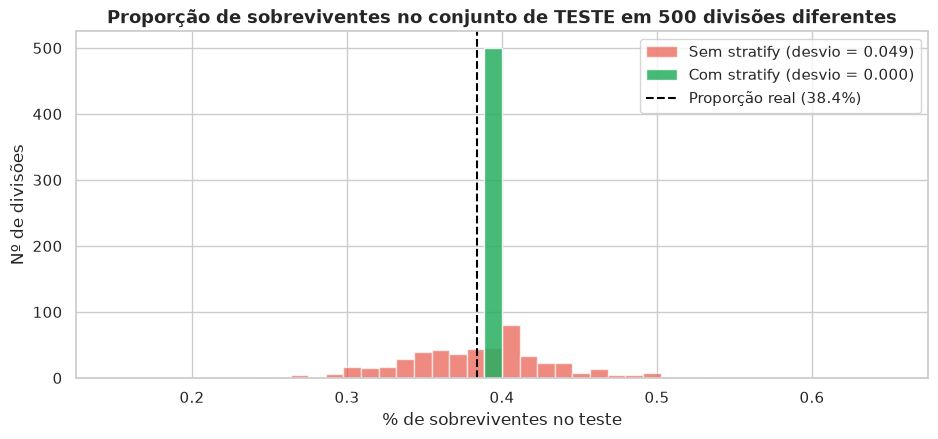

👉 Sem stratify, o teste às vezes fica com 25% ou 50% de sobreviventes (sorte/azar).
   Com stratify, a proporção fica praticamente travada no valor real. Avaliação muito mais justa!


In [37]:
from sklearn.model_selection import train_test_split

X = df[["pclass", "age", "fare"]]
y = df["survived"]

taxa_sem, taxa_com = [], []
for seed in range(500):
    # SEM estratificação
    _, _, _, y_te = train_test_split(X, y, test_size=0.1, random_state=seed)
    taxa_sem.append(y_te.mean())
    # COM estratificação
    _, _, _, y_te = train_test_split(X, y, test_size=0.1, random_state=seed, stratify=y)
    taxa_com.append(y_te.mean())

fig, ax = plt.subplots(figsize=(11, 4.5))
bins = np.linspace(0.15, 0.65, 45)
ax.hist(taxa_sem, bins=bins, alpha=0.65, color="#e74c3c", label=f"Sem stratify (desvio = {np.std(taxa_sem):.3f})")
ax.hist(taxa_com, bins=bins, alpha=0.85, color="#27ae60", label=f"Com stratify (desvio = {np.std(taxa_com):.3f})")
ax.axvline(y.mean(), color="black", ls="--", label=f"Proporção real ({y.mean():.1%})")
ax.set_title("Proporção de sobreviventes no conjunto de TESTE em 500 divisões diferentes")
ax.set_xlabel("% de sobreviventes no teste")
ax.set_ylabel("Nº de divisões")
ax.legend()
plt.show()

print("👉 Sem stratify, o teste às vezes fica com 25% ou 50% de sobreviventes (sorte/azar).")
print("   Com stratify, a proporção fica praticamente travada no valor real. Avaliação muito mais justa!")

---
# 👥 MÓDULO 2 — Análise de Distribuições no Titanic

> ⏱️ **10 minutos**

## A intuição: o "formato" dos dados

Uma **distribuição** responde: *"Quais valores aparecem com mais frequência, e quais são raros?"*
Pense numa fila de pessoas organizadas por altura: o desenho que essa fila forma é a distribuição.

Existem três "formatos" que você verá **o tempo todo** em Ciência de Dados:

| Formato | Aparência | Exemplo do dia a dia | No Titanic |
|---|---|---|---|
| **1. Binária / Categórica** | Poucas barras (2 ou mais categorias) | Cara ou coroa, sim ou não | `survived`, `sex`, `pclass` |
| **2. Simétrica (Sino / Normal)** | Pico no meio, caudas iguais dos dois lados | Altura das pessoas, notas de uma prova | `age` *(aproximadamente)* |
| **3. Assimétrica (Cauda Longa)** | Muitos valores pequenos e **poucos gigantes** | Salários, preços de imóveis, seguidores em redes sociais | `fare` |

### 🧮 Média vs. Mediana: o "detector" de assimetria
- Em dados **simétricos**: média ≈ mediana.
- Em dados de **cauda longa**: a **média é puxada** pelos valores gigantes (pense em um bilionário entrando num bar: a renda média do bar explode, mas a mediana quase não muda).

### Por que isso importa para a IA?
Muitos algoritmos (**Regressão Logística, KNN, SVM, Redes Neurais**) são sensíveis a valores extremos e a escalas. Uma cauda longa pode "sequestrar" o modelo.

---
### 🎨 Primeiro, os três formatos "de laboratório" (dados simulados)

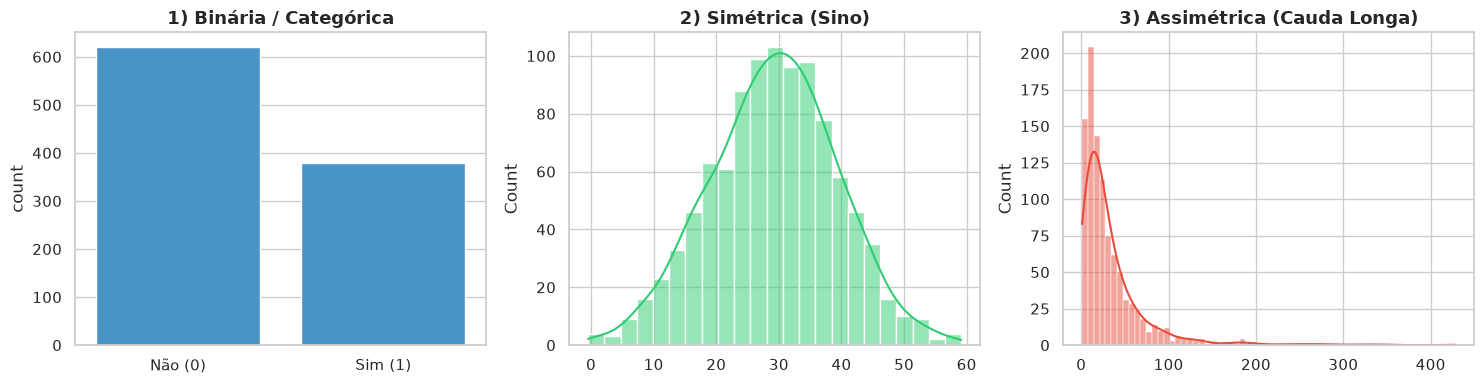

In [38]:
rng = np.random.default_rng(SEED)
binaria = rng.binomial(1, 0.38, 1000)         # tipo "sobreviveu ou não"
sino = rng.normal(30, 10, 1000)               # simétrica
cauda = rng.lognormal(mean=3, sigma=1, size=1000)  # cauda longa

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x=binaria, ax=axes[0], color="#3498db")
axes[0].set_title("1) Binária / Categórica")
axes[0].set_xticklabels(["Não (0)", "Sim (1)"])

sns.histplot(sino, kde=True, ax=axes[1], color="#2ecc71")
axes[1].set_title("2) Simétrica (Sino)")

sns.histplot(cauda, kde=True, ax=axes[2], color="#e74c3c")
axes[2].set_title("3) Assimétrica (Cauda Longa)")
plt.tight_layout()
plt.show()

### 🚢 Agora no Titanic real: `survived`, `age` e `fare`

As linhas **tracejadas** mostram a **média** (vermelha) e a **mediana** (verde). Observe a distância entre elas!

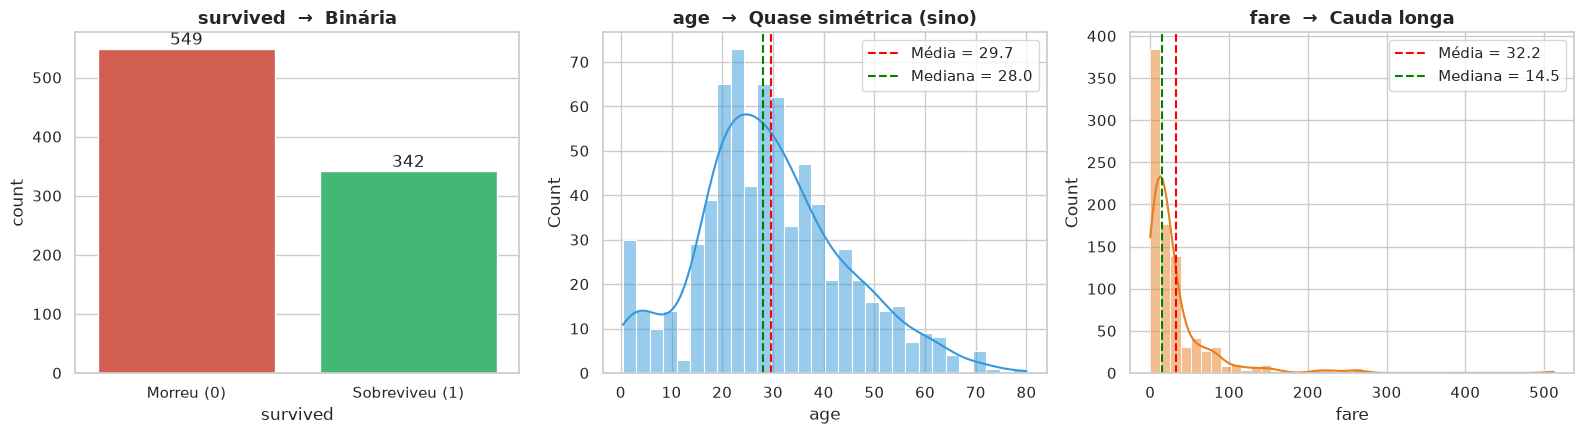

,assimetria (skew),média,mediana
age,0.39,29.7,28.00
fare,4.79,32.2,14.45


👉 'fare': skew ≈ 4.8 e média (32) MUITO maior que a mediana (14). Um passageiro pagou 512 — os 'bilionários do bar'!


In [39]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1) survived: binária
sns.countplot(data=df, x="survived", ax=axes[0], palette=["#e74c3c", "#2ecc71"])
axes[0].set_xticklabels(["Morreu (0)", "Sobreviveu (1)"])
axes[0].set_title("survived  →  Binária")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.0f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")

# 2) age: aproximadamente simétrica
idade = df["age"].dropna()
sns.histplot(idade, kde=True, ax=axes[1], color="#3498db", bins=30)
axes[1].axvline(idade.mean(), color="red", ls="--", label=f"Média = {idade.mean():.1f}")
axes[1].axvline(idade.median(), color="green", ls="--", label=f"Mediana = {idade.median():.1f}")
axes[1].set_title("age  →  Quase simétrica (sino)")
axes[1].legend()

# 3) fare: cauda longa
sns.histplot(df["fare"], kde=True, ax=axes[2], color="#e67e22", bins=40)
axes[2].axvline(df["fare"].mean(), color="red", ls="--", label=f"Média = {df['fare'].mean():.1f}")
axes[2].axvline(df["fare"].median(), color="green", ls="--", label=f"Mediana = {df['fare'].median():.1f}")
axes[2].set_title("fare  →  Cauda longa")
axes[2].legend()

plt.tight_layout()
plt.show()

# Medida numérica de assimetria (skewness):  0 = simétrica | >1 = cauda longa à direita
assimetria = pd.DataFrame({
    "assimetria (skew)": df[["age", "fare"]].skew(),
    "média": df[["age", "fare"]].mean(),
    "mediana": df[["age", "fare"]].median(),
})
display(assimetria.round(2))
print("👉 'fare': skew ≈ 4.8 e média (32) MUITO maior que a mediana (14). Um passageiro pagou 512 — os 'bilionários do bar'!")

## 🪄 O truque de IA: a transformação logarítmica `np.log1p()`

### A intuição
O logaritmo **"comprime" números grandes** e **"estica" os pequenos**, como um zoom que aproxima os gigantes da multidão.

| `fare` original | `log1p(fare)` |
|---|---|
| 0 | 0.00 |
| 10 | 2.40 |
| 100 | 4.62 |
| 512 | 6.24 |

Perceba: a distância entre 100 e 512 na escala original é **412**, mas depois do log é só **1,6**.

> **Por que `log1p` e não `log`?** `log1p(x) = log(1 + x)`. Como existem tarifas **iguais a zero** (`log(0)` é indefinido!), somamos 1 antes. É o "log seguro".

### Por que isso ajuda modelos baseados em distância?
Algoritmos como **KNN, SVM e Regressão Logística com regularização** medem **distâncias** entre pontos. Sem o log, um passageiro que pagou 512 fica "a quilômetros" dos demais e **domina** o cálculo.

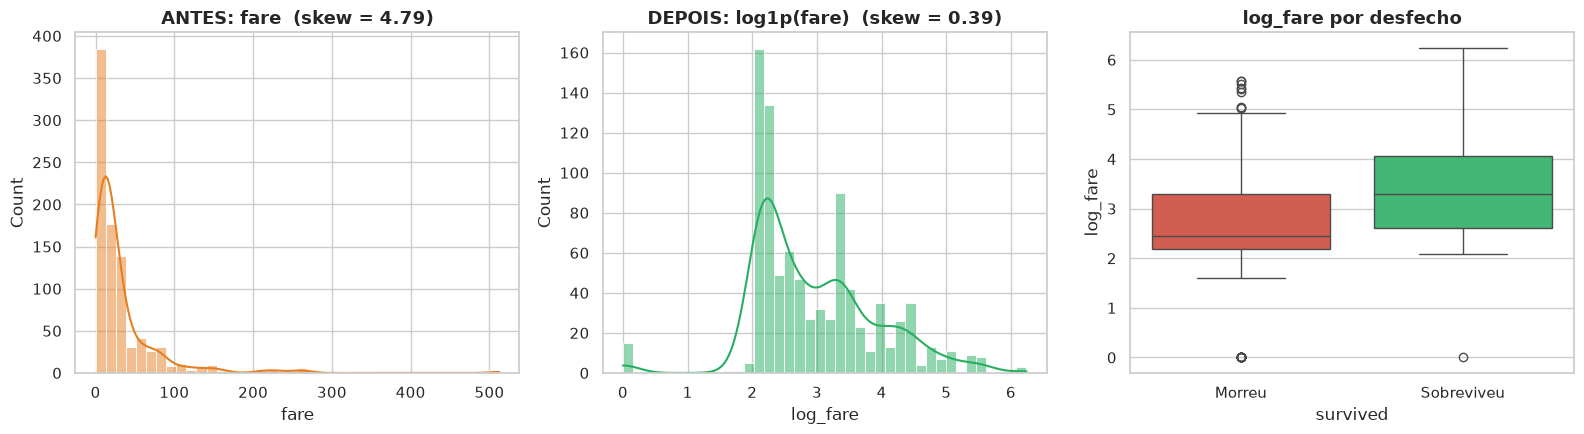

✅ Assimetria caiu de 4.79 para 0.39: muito mais próxima de um sino!


In [40]:
df["log_fare"] = np.log1p(df["fare"])    # 🪄 o truque

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df["fare"], kde=True, ax=axes[0], color="#e67e22", bins=40)
axes[0].set_title(f"ANTES: fare  (skew = {df['fare'].skew():.2f})")

sns.histplot(df["log_fare"], kde=True, ax=axes[1], color="#27ae60", bins=40)
axes[1].set_title(f"DEPOIS: log1p(fare)  (skew = {df['log_fare'].skew():.2f})")

# Relação com o alvo: o log melhora a visualização da diferença entre grupos
sns.boxplot(data=df, x="survived", y="log_fare", ax=axes[2], palette=["#e74c3c", "#2ecc71"])
axes[2].set_xticklabels(["Morreu", "Sobreviveu"])
axes[2].set_title("log_fare por desfecho")
plt.tight_layout()
plt.show()

print(f"✅ Assimetria caiu de {df['fare'].skew():.2f} para {df['log_fare'].skew():.2f}: muito mais próxima de um sino!")

### 📏 Demonstração: por que a escala "sequestra" modelos de distância

Imagine 3 passageiros. Qual dupla é **mais parecida**, **A e B** (mesma idade, tarifas bem diferentes) ou **A e C** (mesma tarifa, 30 anos de diferença)?

| | Idade | Tarifa |
|---|---|---|
| **A** | 30 | 10 |
| **B** | 30 | 100 |
| **C** | 60 | 10 |

Vamos medir a **distância euclidiana** (a "régua" que KNN/SVM usam) em três etapas: bruto → com log → com log + Score Z.

In [41]:
idade_media, idade_dp = df["age"].mean(), df["age"].std()
lf_media, lf_dp = df["log_fare"].mean(), df["log_fare"].std()

A = {"age": 30, "fare": 10}
B = {"age": 30, "fare": 100}
C = {"age": 60, "fare": 10}

def vetor(p, etapa):
    idade, tarifa = p["age"], p["fare"]
    if etapa == "1) Dados brutos":
        return np.array([idade, tarifa])
    if etapa == "2) Só log1p(fare)":
        return np.array([idade, np.log1p(tarifa)])
    if etapa == "3) log1p + Score Z":
        return np.array([(idade - idade_media) / idade_dp, (np.log1p(tarifa) - lf_media) / lf_dp])

linhas = []
for etapa in ["1) Dados brutos", "2) Só log1p(fare)", "3) log1p + Score Z"]:
    d_ab = np.linalg.norm(vetor(A, etapa) - vetor(B, etapa))
    d_ac = np.linalg.norm(vetor(A, etapa) - vetor(C, etapa))
    linhas.append({"etapa": etapa, "distância A–B (tarifa difere)": d_ab, "distância A–C (idade difere)": d_ac,
                   "mais parecido com A": "B" if d_ab < d_ac else "C"})
display(pd.DataFrame(linhas).set_index("etapa").round(2))

print("👉 Nos dados brutos, A é 'mais parecido' com C só porque a TARIFA (em dólares) grita mais alto que a IDADE (em anos).")
print("   Só o log NÃO basta: a idade (30 anos) ainda domina a tarifa em log (2,2) e A passa a parecer \"mais parecido com B\" por distorção inversa.")
print("   Após log + Score Z, as duas features passam a ter voz equilibrada (2,29 vs 2,07). Os truques funcionam EM CONJUNTO!")

,distância A–B (tarifa difere),distância A–C (idade difere),mais parecido com A
etapa,,,
1) Dados brutos,90.00,30.00,C
2) Só log1p(fare),2.22,30.00,B
3) log1p + Score Z,2.29,2.07,C


👉 Nos dados brutos, A é 'mais parecido' com C só porque a TARIFA (em dólares) grita mais alto que a IDADE (em anos).
   Só o log NÃO basta: a idade (30 anos) ainda domina a tarifa em log (2,2) e A passa a parecer "mais parecido com B" por distorção inversa.
   Após log + Score Z, as duas features passam a ter voz equilibrada (2,29 vs 2,07). Os truques funcionam EM CONJUNTO!


---
# ⚖️ MÓDULO 4 — Testes de Hipóteses Sem Mistério
## (O "Detector de Mentiras" das Features)

> ⏱️ **12 minutos**

## A Lógica do Tribunal

Um julgamento é o melhor modelo mental para um teste de hipóteses:

| No tribunal | Na estatística |
|---|---|
| O réu é **inocente até que se prove o contrário** | **H₀ (Hipótese Nula):** "**Não existe** relação/diferença. Qualquer padrão é obra do acaso." |
| A acusação tenta provar culpa | **H₁ (Hipótese Alternativa):** "**Existe** relação/diferença real." |
| As **provas** | Os **dados** |
| "Culpado além de qualquer dúvida razoável" | **p-valor < 0,05** |
| Veredito: culpado / não há provas suficientes | **Rejeitar H₀** / **Não rejeitar H₀** |

> ⚠️ Repare: o juiz nunca diz "provado inocente", só "**sem provas suficientes**". Do mesmo jeito, **não rejeitar H₀ não prova que não há relação**: apenas que os dados não mostraram evidência forte.

## 🎲 O que é o valor-p, afinal?

> **valor-p = a probabilidade de observar dados tão "estranhos" quanto os nossos, SE a H₀ fosse verdadeira.**

- **p pequeno (< 0,05):** "Se fosse só acaso, seria muito improvável ver isso." → **Rejeitamos H₀** (a feature provavelmente importa!).
- **p grande (≥ 0,05):** "Isso poderia perfeitamente acontecer por acaso." → **Não rejeitamos H₀**.

### 🪙 Intuição com uma moeda
Jogamos uma moeda **100 vezes** e saíram **60 caras**. A moeda é viciada?
- **H₀:** a moeda é justa (50%).
- Vamos **simular 100.000 moedas justas** e ver com que frequência saem resultados tão extremos quanto 60 (ou 40) caras.

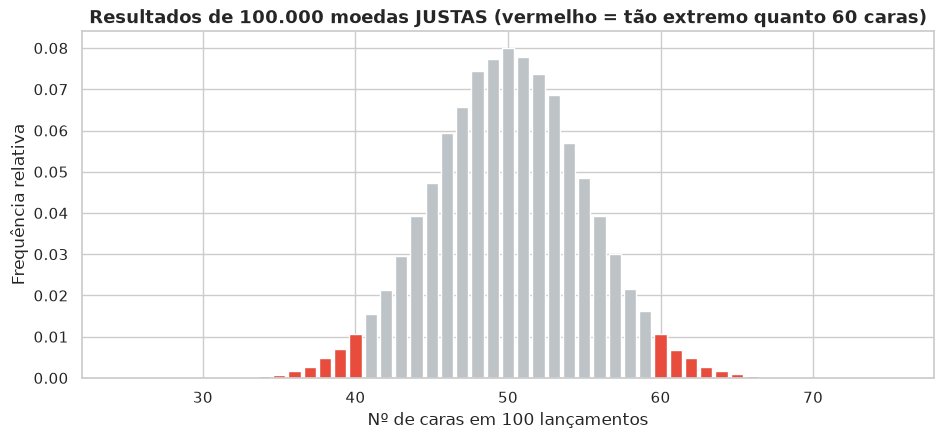

p-valor por simulação (a área vermelha) : 0.057
p-valor do teste estatístico (binomial) : 0.057

👉 p ≈ 0,06 > 0,05: com 60 caras NÃO temos evidência forte de que a moeda é viciada. Poderia ser só acaso!
   O valor-p é, literalmente, a ÁREA VERMELHA do gráfico.


In [46]:
rng = np.random.default_rng(SEED)
caras = rng.binomial(n=100, p=0.5, size=100_000)          # 100 mil "universos" onde a moeda é JUSTA

p_simulado = np.mean(np.abs(caras - 50) >= 10)            # tão ou mais extremo que 60 caras (ou 40)
p_teste = stats.binomtest(k=60, n=100, p=0.5).pvalue      # o teste estatístico "oficial"

fig, ax = plt.subplots(figsize=(11, 4.5))
valores = np.arange(25, 76)
contagem = np.bincount(caras, minlength=101)[25:76] / len(caras)
cores = ["#e74c3c" if abs(v - 50) >= 10 else "#bdc3c7" for v in valores]
ax.bar(valores, contagem, color=cores)
ax.set_title("Resultados de 100.000 moedas JUSTAS (vermelho = tão extremo quanto 60 caras)")
ax.set_xlabel("Nº de caras em 100 lançamentos")
ax.set_ylabel("Frequência relativa")
plt.show()

print(f"p-valor por simulação (a área vermelha) : {p_simulado:.3f}")
print(f"p-valor do teste estatístico (binomial) : {p_teste:.3f}")
print("\n👉 p ≈ 0,06 > 0,05: com 60 caras NÃO temos evidência forte de que a moeda é viciada. Poderia ser só acaso!")
print("   O valor-p é, literalmente, a ÁREA VERMELHA do gráfico.")

## 🧰 Os 2 testes mais populares para Feature Selection

A escolha do teste depende do **tipo** das duas variáveis comparadas:

| Feature | Alvo | Teste | Pergunta que responde |
|---|---|---|---|
| **Categórica** (sex, pclass, embarked) | Categórico (survived) | **Qui-Quadrado ($\chi^2$)** | "A distribuição do alvo muda entre as categorias?" |
| **Numérica** (age, fare) | Categórico binário (survived) | **Teste t de Student** | "A **média** da feature é diferente entre os grupos?" |

---
## 🧪 Teste 1 — Qui-Quadrado ($\chi^2$): Categoria vs. Categoria

### A intuição
Comparamos o que **observamos** com o que **esperaríamos se as variáveis fossem independentes** (H₀). Se a distância entre "observado" e "esperado" for grande, desconfiamos de que há relação.

- **H₀:** `sex` e `survived` são **independentes** (o sexo não influencia a sobrevivência).
- **H₁:** `sex` e `survived` estão **associados**.

$$ \chi^2 = \sum \frac{(\text{Observado} - \text{Esperado})^2}{\text{Esperado}} $$

In [72]:
obs = pd.crosstab(df["sex"], df["survived"])
obs.columns = ["Morreu", "Sobreviveu"]
print("📋 OBSERVADO:")
display(obs)

chi2, p_valor, gl, esperado = stats.chi2_contingency(pd.crosstab(df["sex"], df["survived"]))
print("ESPERADO:")
display(pd.DataFrame(esperado, index=obs.index, columns=obs.columns))


📋 OBSERVADO:


,Morreu,Sobreviveu
sex,,
female,81,233
male,468,109


ESPERADO:


,Morreu,Sobreviveu
sex,,
female,193.474747,120.525253
male,355.525253,221.474747


---
# 👯 MÓDULO 5 — Correlação e Multicolinearidade

> ⏱️ **6 minutos**

## A intuição: de -1 a +1

A **correlação de Pearson ($r$)** mede o quanto duas variáveis numéricas **andam juntas em linha reta**.

| Valor de $r$ | Significado | Exemplo do dia a dia |
|---|---|---|
| **+1** | Quando uma sobe, a outra sobe **sempre** | Altura em cm vs. altura em polegadas |
| **+0,7** | Sobem juntas na maioria das vezes | Horas de estudo vs. nota |
| **0** | **Nenhuma** relação linear | Tamanho do sapato vs. nota em matemática |
| **-0,7** | Quando uma sobe, a outra tende a descer | Preço do produto vs. quantidade vendida |
| **-1** | Quando uma sobe, a outra desce **sempre** | Litros no tanque vs. km rodados |

### 👯 Multicolinearidade: o problema dos "clones"
Quando **duas features** (ou mais) têm correlação muito alta entre si ($|r| > 0{,}7$ ~ $0{,}8$), elas carregam **a mesma informação**. Isso:
- 😵 **Confunde** modelos lineares (os coeficientes ficam instáveis e difíceis de interpretar).
- 🐢 **Gasta processamento** à toa e aumenta o risco de *overfitting*.
- 🕵️ **Pode esconder vazamento de dados** (*data leakage*): se uma feature tem correlação ≈ 1 com o **alvo**, desconfie! Provavelmente ela "entrega a resposta".

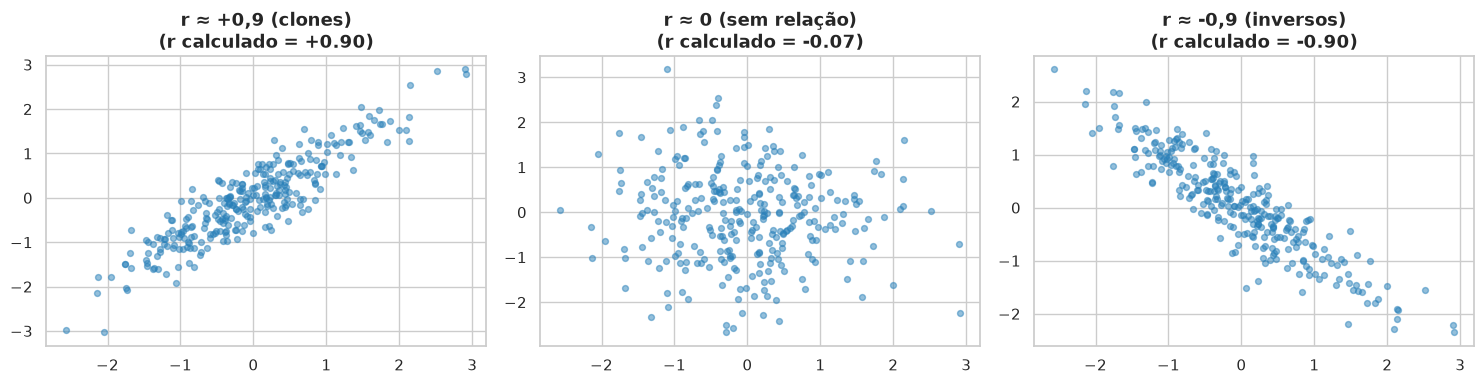

In [51]:
rng = np.random.default_rng(SEED)
n = 300
base = rng.normal(size=n)
casos = {
    "r ≈ +0,9 (clones)": base * 0.9 + rng.normal(scale=0.4, size=n),
    "r ≈ 0 (sem relação)": rng.normal(size=n),
    "r ≈ -0,9 (inversos)": -base * 0.9 + rng.normal(scale=0.4, size=n),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (titulo, yy) in zip(axes, casos.items()):
    r = np.corrcoef(base, yy)[0, 1]
    ax.scatter(base, yy, alpha=0.5, s=18, color="#2980b9")
    ax.set_title(f"{titulo}\n(r calculado = {r:+.2f})")
plt.tight_layout()
plt.show()

### 🔥 O Mapa de Calor (Heatmap) do Titanic

Vamos preparar uma tabela só com números (convertendo as categorias binárias em 0/1) e desenhar a **matriz de correlação**.
Cores **quentes** (vermelho) = correlação positiva | Cores **frias** (azul) = correlação negativa.

> Incluímos propositalmente algumas colunas "suspeitas" do dataset: `adult_male` (parente de `sex`) e `alive_num` (será que é parente do alvo?).

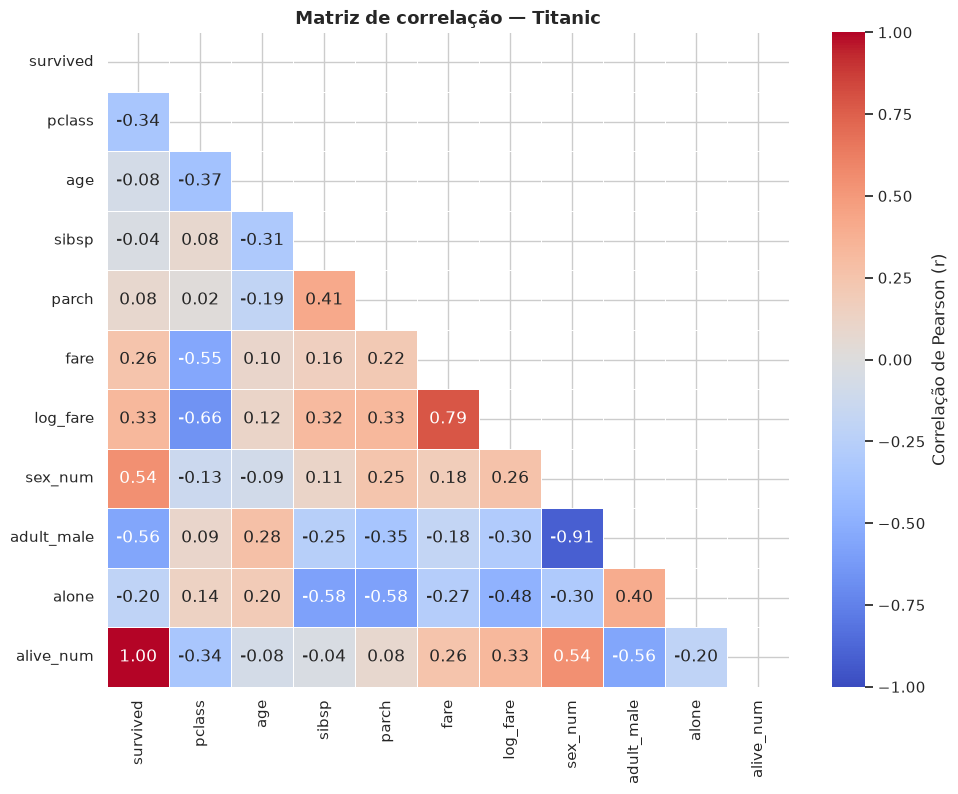

In [52]:
df_corr = df[["survived", "pclass", "age", "sibsp", "parch", "fare", "log_fare"]].copy()
df_corr["sex_num"] = (df["sex"] == "female").astype(int)        # 1 = mulher
df_corr["adult_male"] = df["adult_male"].astype(int)
df_corr["alone"] = df["alone"].astype(int)
df_corr["alive_num"] = (df["alive"] == "yes").astype(int)       # coluna suspeita!

corr = df_corr.corr()

fig, ax = plt.subplots(figsize=(11, 8.5))
mascara = np.triu(np.ones_like(corr, dtype=bool))               # esconde a metade repetida
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Correlação de Pearson (r)"}, ax=ax)
ax.set_title("Matriz de correlação — Titanic")
plt.show()

In [73]:
df_corr = df[["survived", "pclass", "age", "sibsp", "parch", "fare", "log_fare"]].copy()
df_corr.corr()['survived']

survived    1.000000
pclass     -0.338481
age        -0.077221
sibsp      -0.035322
parch       0.081629
fare        0.257307
log_fare    0.329862
Name: survived, dtype: float64

---
# 🏁 Exemplo de Otimização de Modelo com Estatística


Chegou a hora de provar que **estatística não é enfeite: ela gera resultados**. Vamos colocar dois modelos de **Regressão Logística** para competir **no mesmo conjunto de teste**:

| | 🤡 Modelo 1 — Ingênuo (**= o teste cego do início**) | 🧠 Modelo 2 — Guiado pela Estatística |
|---|---|---|
| **Dados nulos** | Preenche com `0` (a "gambiarra") | **Imputação pela mediana da classe** (`pclass`), aprendida só no treino |
| **Escala** | Dados brutos | **Score Z** (`StandardScaler`) |
| **Tarifa** | `fare` bruta (cauda longa) | **`log1p(fare)`** |
| **Engenharia de features** | Nenhuma | **`eh_crianca`** (derivada da curva normal) |
| **Seleção de features** | Todas as numéricas, "no escuro" | **Só as aprovadas** nos testes de hipóteses (Qui² e t) |
| **Features categóricas** | Ignoradas | `sex`, `pclass`, `embarked`, `alone` (se aprovadas) |

### 🛡️ Cuidados profissionais embutidos
- **Estratificação** (`stratify=y`) na divisão treino/teste (Módulo 1).
- Medianas, médias, desvios e **testes de hipóteses** calculados **apenas no treino**, para o teste continuar sendo uma "prova surpresa" honesta (sem *data leakage*).
- Nenhuma coluna clone do alvo (`alive`) é usada.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

ALVO = "survived"
COLS_BRUTAS = ["pclass", "age", "sibsp", "parch", "fare"]          # o que o "ingênuo" encontra de numérico

CAT = ["sex", "pclass", "embarked", "alone", "eh_crianca"]          # candidatas categóricas (Qui-Quadrado)
NUM = ["age", "log_fare", "sibsp", "parch"]                         # candidatas numéricas (Teste t)
MULTI = ["sex", "pclass", "embarked"]                               # categóricas que viram dummies (one-hot)


def dividir(seed=SEED):
    """Divisão estratificada treino/teste (Módulo 1)."""
    return train_test_split(df, test_size=0.2, stratify=df[ALVO], random_state=seed)


# ----------------------------------------------------------------------------
# 🤡 MODELO 1 — INGÊNUO
# ----------------------------------------------------------------------------
def rodar_modelo_ingenuo(treino, teste):
    Xtr = treino[COLS_BRUTAS].fillna(0)      # nulos viram zero (idade 0 anos!?)
    Xte = teste[COLS_BRUTAS].fillna(0)
    modelo = LogisticRegression(max_iter=1000)
    modelo.fit(Xtr, treino[ALVO])
    pred = modelo.predict(Xte)
    return accuracy_score(teste[ALVO], pred), pred


# ----------------------------------------------------------------------------
# 🧠 MODELO 2 — GUIADO PELA ESTATÍSTICA
# ----------------------------------------------------------------------------
def engenharia_de_features(treino, teste):
    """Imputação, log e feature nova. Tudo que é 'aprendido' vem do TREINO."""
    treino, teste = treino.copy(), teste.copy()
    med_idade_por_classe = treino.groupby("pclass")["age"].median()     # mediana da classe
    moda_embarque = treino["embarked"].mode()[0]
    for d in (treino, teste):
        d["age"] = d["age"].fillna(d["pclass"].map(med_idade_por_classe))
        d["embarked"] = d["embarked"].fillna(moda_embarque)
        d["log_fare"] = np.log1p(d["fare"])
        d["eh_crianca"] = (d["age"] < 15).astype(int)
        d["alone"] = d["alone"].astype(int)
    return treino, teste


def selecionar_features(treino, alpha=0.05):
    """Aplica Qui-Quadrado (categóricas) e Teste t (numéricas) SOMENTE no treino."""
    registro = []
    for c in CAT:
        _, p, _, _ = stats.chi2_contingency(pd.crosstab(treino[c], treino[ALVO]))
        registro.append({"feature": c, "teste": "Qui-Quadrado", "p_valor": p})
    for c in NUM:
        a = treino.loc[treino[ALVO] == 1, c]
        b = treino.loc[treino[ALVO] == 0, c]
        _, p = stats.ttest_ind(a, b, equal_var=False)
        registro.append({"feature": c, "teste": "Teste t", "p_valor": p})
    registro = pd.DataFrame(registro).sort_values("p_valor").reset_index(drop=True)
    registro["aprovada"] = registro["p_valor"] < alpha
    return registro["feature"][registro["aprovada"]].tolist(), registro


def montar_matriz(treino, teste, aprovadas):
    cols = [c for c in CAT + NUM if c in aprovadas]
    dummies = [c for c in cols if c in MULTI]
    Xtr = pd.get_dummies(treino[cols], columns=dummies, drop_first=True, dtype=int)
    Xte = pd.get_dummies(teste[cols], columns=dummies, drop_first=True, dtype=int)
    Xte = Xte.reindex(columns=Xtr.columns, fill_value=0)
    return Xtr, Xte


def rodar_modelo_guiado(treino, teste):
    treino, teste = engenharia_de_features(treino, teste)
    aprovadas, registro = selecionar_features(treino)
    Xtr, Xte = montar_matriz(treino, teste, aprovadas)

    escala = StandardScaler().fit(Xtr)                           # Score Z aprendido no treino
    Xtr_z = pd.DataFrame(escala.transform(Xtr), columns=Xtr.columns, index=Xtr.index)
    Xte_z = pd.DataFrame(escala.transform(Xte), columns=Xte.columns, index=Xte.index)

    modelo = LogisticRegression(max_iter=1000)
    modelo.fit(Xtr_z, treino[ALVO])
    pred = modelo.predict(Xte_z)
    return accuracy_score(teste[ALVO], pred), pred, modelo, list(Xtr.columns), registro, aprovadas


print("✅ Funções dos dois modelos definidas. Vamos à corrida!")

✅ Funções dos dois modelos definidas. Vamos à corrida!


### 🏎️ A corrida: Modelo 1 vs. Modelo 2 (mesma divisão treino/teste)

🧪 Features avaliadas pelos testes de hipóteses (APENAS no treino):


,feature,teste,p_valor,aprovada
0,sex,Qui-Quadrado,4.16e-48,True
1,log_fare,Teste t,2.62e-21,True
2,pclass,Qui-Quadrado,1.89e-19,True
3,alone,Qui-Quadrado,1.40e-08,True
4,embarked,Qui-Quadrado,2.98e-06,True
5,eh_crianca,Qui-Quadrado,2.21e-03,True
6,parch,Teste t,2.22e-02,True
7,age,Teste t,1.55e-01,False
8,sibsp,Teste t,4.32e-01,False



✅ Features que entraram no Modelo 2: ['sex', 'log_fare', 'pclass', 'alone', 'embarked', 'eh_crianca', 'parch']

🤡 Modelo 1 (Ingênuo)               → acurácia = 66.5%
🧠 Modelo 2 (Guiado pela Estatística) → acurácia = 78.8%
🚀 SALTO REAL DE ACURÁCIA            → +12.3 pontos percentuais


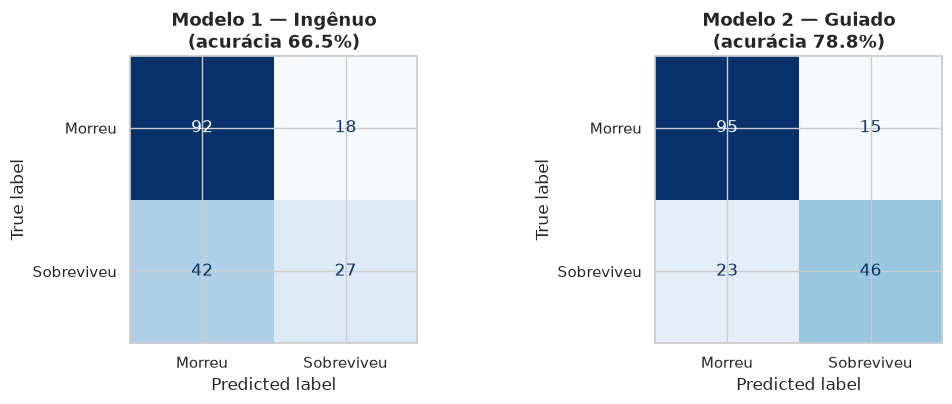

In [57]:
treino, teste = dividir(SEED)

acc1, pred1 = rodar_modelo_ingenuo(treino, teste)
acc2, pred2, modelo2, colunas2, registro, aprovadas = rodar_modelo_guiado(treino, teste)

print("🧪 Features avaliadas pelos testes de hipóteses (APENAS no treino):")
display(registro.style.format({"p_valor": "{:.2e}"}))
print(f"\n✅ Features que entraram no Modelo 2: {aprovadas}\n")

print("=" * 55)
print(f"🤡 Modelo 1 (Ingênuo)               → acurácia = {acc1:.1%}")
print(f"🧠 Modelo 2 (Guiado pela Estatística) → acurácia = {acc2:.1%}")
print(f"🚀 SALTO REAL DE ACURÁCIA            → {100 * (acc2 - acc1):+.1f} pontos percentuais")
print("=" * 55)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, pred, titulo in zip(axes, [pred1, pred2], [f"Modelo 1 — Ingênuo\n(acurácia {acc1:.1%})", f"Modelo 2 — Guiado\n(acurácia {acc2:.1%})"]):
    ConfusionMatrixDisplay.from_predictions(teste[ALVO], pred, ax=ax, cmap="Blues", colorbar=False,
                                            display_labels=["Morreu", "Sobreviveu"])
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

### 🔁 Foi sorte? Repetindo o experimento com 30 divisões diferentes

Uma única divisão pode favorecer um modelo por acaso (lembra da panela de sopa? 🍲). Vamos repetir tudo — **incluindo os testes de hipóteses** — com 30 sementes diferentes e ver se o ganho se mantém.

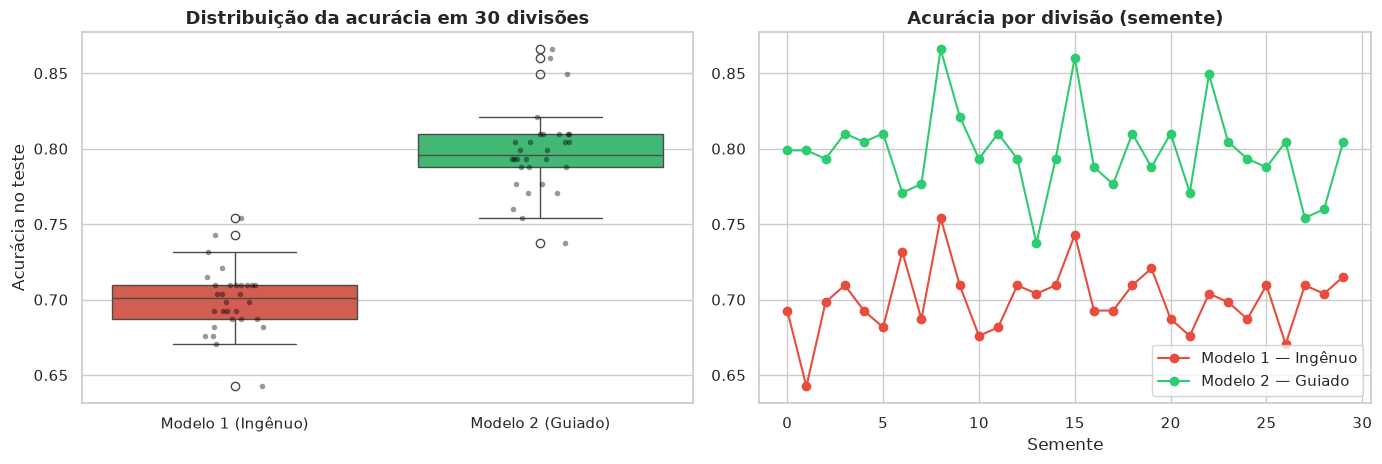

Acurácia média — Modelo 1: 70.0% | Modelo 2: 79.8%
Ganho médio: +9.8 pontos percentuais
Modelo 2 venceu em 30 de 30 divisões
Teste t pareado do ganho: p-valor = 2.22e-17  →  diferença REAL, não é acaso!


In [58]:
resultados = []
for s in range(30):
    tr, te = dividir(s)
    a1, _ = rodar_modelo_ingenuo(tr, te)
    a2, *_ = rodar_modelo_guiado(tr, te)
    resultados.append({"semente": s, "Modelo 1 (Ingênuo)": a1, "Modelo 2 (Guiado)": a2})
res = pd.DataFrame(resultados).set_index("semente")

# Teste t PAREADO: as duas acurácias vêm das MESMAS divisões (usando o que aprendemos!)
t, p = stats.ttest_rel(res["Modelo 2 (Guiado)"], res["Modelo 1 (Ingênuo)"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=res, ax=axes[0], palette=["#e74c3c", "#2ecc71"])
sns.stripplot(data=res, ax=axes[0], color="black", alpha=0.4, size=4)
axes[0].set_title("Distribuição da acurácia em 30 divisões")
axes[0].set_ylabel("Acurácia no teste")

axes[1].plot(res.index, res["Modelo 1 (Ingênuo)"], "o-", color="#e74c3c", label="Modelo 1 — Ingênuo")
axes[1].plot(res.index, res["Modelo 2 (Guiado)"], "o-", color="#2ecc71", label="Modelo 2 — Guiado")
axes[1].set_title("Acurácia por divisão (semente)")
axes[1].set_xlabel("Semente")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Acurácia média — Modelo 1: {res.iloc[:, 0].mean():.1%} | Modelo 2: {res.iloc[:, 1].mean():.1%}")
print(f"Ganho médio: {100 * (res.iloc[:, 1] - res.iloc[:, 0]).mean():+.1f} pontos percentuais")
print(f"Modelo 2 venceu em {(res.iloc[:, 1] > res.iloc[:, 0]).sum()} de 30 divisões")
print(f"Teste t pareado do ganho: p-valor = {p:.2e}  →  {'diferença REAL, não é acaso!' if p < 0.05 else 'pode ser acaso.'}")

---
## 🪜 A Escadinha: quanto cada etapa da aula contribuiu?

Voltamos ao **teste cego** do início. Em vez de pular direto do Modelo 1 para o Modelo 2, vamos **subir degrau por degrau**, ligando **uma etapa de preparação por vez**:

| Degrau | O que foi adicionado | Aula de origem |
|---|---|---|
| **0** | Baseline: dados crus, nulos = 0 | 🎲 Teste cego |
| **1** | + Imputação de `age` pela **mediana da classe** | Módulo 2 (EDA dos nulos e da distribuição) |
| **2** | + `log1p(fare)` e **Score Z** | Módulos 2 e 3 |
| **3** | + Features categóricas (`sex`, `embarked`, `alone`) | Módulo 4 (Qui-Quadrado) |
| **4** | + Feature `eh_crianca` | Módulo 3 (curva normal) |
| **5** | + **Seleção por testes de hipóteses** (modelo guiado completo, mais enxuto) | Módulo 4 |

> A coluna "média de 30 divisões" mostra se o resultado se sustenta **além de uma divisão específica**.

In [59]:
def rodar_degrau(treino, teste, imputar=False, log=False, escalar=False, categoricas=False, crianca=False):
    # Liga/desliga cada etapa de preparação para medir sua contribuição isolada
    treino, teste = treino.copy(), teste.copy()
    med = treino.groupby("pclass")["age"].median()
    moda = treino["embarked"].mode()[0]
    for d in (treino, teste):
        d["age"] = d["age"].fillna(d["pclass"].map(med)) if imputar else d["age"].fillna(0)
        d["embarked"] = d["embarked"].fillna(moda)
        d["alone"] = d["alone"].astype(int)
        d["eh_crianca"] = (d["age"] < 15).astype(int)
        d["fare_usada"] = np.log1p(d["fare"]) if log else d["fare"]

    cols = ["pclass", "age", "sibsp", "parch", "fare_usada"]
    dummies = []
    if categoricas:
        cols += ["sex", "embarked", "alone"]
        dummies = ["sex", "embarked"]
    if crianca:
        cols.append("eh_crianca")

    Xtr = pd.get_dummies(treino[cols], columns=dummies, drop_first=True, dtype=int)
    Xte = pd.get_dummies(teste[cols], columns=dummies, drop_first=True, dtype=int).reindex(columns=Xtr.columns, fill_value=0)
    if escalar:
        esc = StandardScaler().fit(Xtr)
        Xtr = pd.DataFrame(esc.transform(Xtr), columns=Xtr.columns, index=Xtr.index)
        Xte = pd.DataFrame(esc.transform(Xte), columns=Xte.columns, index=Xte.index)

    modelo = LogisticRegression(max_iter=1000).fit(Xtr, treino[ALVO])
    return accuracy_score(teste[ALVO], modelo.predict(Xte))


degraus = [
    ("0) Baseline\n(teste cego)",              dict()),
    ("1) + Imputação\npela mediana",           dict(imputar=True)),
    ("2) + log1p\n+ Score Z",                  dict(imputar=True, log=True, escalar=True)),
    ("3) + sex, embarked,\nalone",             dict(imputar=True, log=True, escalar=True, categoricas=True)),
    ("4) + eh_crianca",                        dict(imputar=True, log=True, escalar=True, categoricas=True, crianca=True)),
    ("5) + Seleção por\ntestes (Modelo 2)",    "guiado"),
]

def acuracia_degrau(config, seed):
    tr, te = dividir(seed)
    if config == "guiado":
        return rodar_modelo_guiado(tr, te)[0]
    return rodar_degrau(tr, te, **config)

unica = [acuracia_degrau(cfg, SEED) for _, cfg in degraus]
medias = []
for _, cfg in degraus:
    accs = [acuracia_degrau(cfg, s) for s in range(30)]
    medias.append((np.mean(accs), np.std(accs)))

print(f"✔️ Degrau 0 reproduz o baseline do início? {np.isclose(unica[0], ACC_BASELINE)}")
print(f"✔️ Degrau 5 reproduz o Modelo 2 do Módulo 6? {np.isclose(unica[5], acc2)}\n")

nomes = [n.replace("\n", " ") for n, _ in degraus]
tabela = pd.DataFrame({
    "acurácia (divisão principal)": unica,
    "ganho vs. degrau anterior (p.p.)": [np.nan] + [100 * (unica[i] - unica[i - 1]) for i in range(1, len(unica))],
    "média de 30 divisões": [m for m, _ in medias],
    "desvio (30 divisões)": [d for _, d in medias],
}, index=nomes)
display(tabela.style.format({"acurácia (divisão principal)": "{:.1%}", "ganho vs. degrau anterior (p.p.)": "{:+.1f}",
                             "média de 30 divisões": "{:.1%}", "desvio (30 divisões)": "{:.3f}"}, na_rep="—"))

fig, ax = plt.subplots(figsize=(12, 5.5))
cores = ["#e74c3c"] + ["#3498db"] * 4 + ["#27ae60"]
barras = ax.bar(range(len(degraus)), unica, color=cores)
ax.axhline(ACC_MAIORIA, color="gray", ls=":", label=f"Chutar 'ninguém sobrevive' ({ACC_MAIORIA:.1%})")
ax.axhline(ACC_BASELINE, color="#e74c3c", ls="--", alpha=0.6, label=f"Baseline do início ({ACC_BASELINE:.1%})")
for i, b in enumerate(barras):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.006, f"{unica[i]:.1%}", ha="center", fontweight="bold")
    if i > 0:
        ganho = 100 * (unica[i] - unica[i - 1])
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() / 2, f"{ganho:+.1f} p.p.", ha="center",
                color="white", fontweight="bold")
ax.set_xticks(range(len(degraus)))
ax.set_xticklabels([n for n, _ in degraus], fontsize=9)
ax.set_ylim(0.5, 0.9)
ax.set_ylabel("Acurácia no teste")
ax.set_title("A Escadinha: de onde vem cada ponto de acurácia")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

total = 100 * (unica[-1] - unica[0])
print(f"🏁 Do teste cego ao modelo guiado: {unica[0]:.1%} → {unica[-1]:.1%}  ({total:+.1f} pontos percentuais)")

NameError: name 'ACC_BASELINE' is not defined

### 🧐 Como ler a escadinha (com honestidade científica)

- **Degraus 1 e 2 (imputação, `log1p`, Score Z): ganho pequeno** em Regressão Logística (≈ +1 p.p. cada). Eles evitam absurdos (idade 0) e deixam os coeficientes comparáveis, mas **não mudam muito a acurácia** deste modelo. Em **KNN, SVM e redes neurais**, a escala e o `log1p` pesariam muito mais.
- **Degrau 3 (`sex`, `embarked`, `alone`): o grande salto (≈ +14 p.p.).** É a feature que o **Qui-Quadrado** apontou como a mais associada ao alvo, e o modelo cego jamais a viu. **Aqui a estatística pagou o ingresso inteiro.**
- **Degraus 4 e 5: variações de 1 a 3 p.p. estão dentro do ruído.** Veja o desvio de ~2 p.p. nas 30 divisões. `eh_crianca` praticamente não muda a acurácia, e a **seleção por testes deixou o modelo mais enxuto** (descartou `age` e `sibsp`) **sem ganho de acurácia**, até com leve queda.
- **Moral da história:** estatística não é "botão de turbinar" em todo degrau. Ela diz **onde o esforço compensa** (sexo e classe) e **onde não compensa**. Um modelo mais simples com a mesma acurácia continua sendo uma vitória: é mais fácil de explicar, manter e auditar.

### 🏆 Ranking de importância das features

Como todas as features do Modelo 2 estão na **mesma régua (Score Z)**, os **coeficientes** da Regressão Logística são diretamente comparáveis:

- **Coeficiente positivo (🟩):** aumenta a chance de sobrevivência.
- **Coeficiente negativo (🟥):** diminui a chance.
- **Tamanho da barra:** força da influência.
- **Razão de chances** $= e^{\text{coef}}$: quanto a chance de sobreviver **é multiplicada** quando a feature sobe 1 desvio padrão. (Ex.: 0,5 → metade da chance; 2,0 → o dobro.)

In [ ]:
coefs = pd.Series(modelo2.coef_[0], index=colunas2)
ordem = coefs.abs().sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
cores = ["#2ecc71" if coefs[c] > 0 else "#e74c3c" for c in ordem.index]
ax.barh(ordem.index, [coefs[c] for c in ordem.index], color=cores)
ax.axvline(0, color="black", lw=1)
ax.set_title("Ranking de importância (coeficientes padronizados — Regressão Logística)")
ax.set_xlabel("Coeficiente (efeito no log da chance de sobreviver)")
for i, c in enumerate(ordem.index):
    ax.text(coefs[c] + (0.03 if coefs[c] > 0 else -0.03), i, f"{coefs[c]:+.2f}",
            va="center", ha="left" if coefs[c] > 0 else "right", fontsize=9)
plt.tight_layout()
plt.show()

tabela_imp = pd.DataFrame({
    "coeficiente": coefs,
    "razão de chances (e^coef)": np.exp(coefs),
}).loc[coefs.abs().sort_values(ascending=False).index]
display(tabela_imp.round(3))

print("👉 O topo do ranking confirma o que os testes de hipóteses e o heatmap já anunciavam: sexo e classe social dominam o jogo.")

### 💬 Discussão honesta (o que um bom cientista de dados diria)

1. **De onde veio o salto?** Boa parte vem de o Modelo 2 *enxergar* `sex` e `pclass` — as features que os **testes de hipóteses** apontaram como mais associadas ao alvo — enquanto o ingênuo as ignorava. Esse é o poder da seleção estatística de features.
2. **O que a imputação e o Score Z adicionam?** Evitam o absurdo de "passageiros com 0 anos" e deixam os coeficientes comparáveis. Em outros algoritmos (KNN, SVM, redes neurais), o impacto da escala e do `log1p` seria **ainda maior**.
3. **Estatística não é mágica:** acuracidade perto de 80% é típica para esse problema com Regressão Logística. Para ir além, o próximo passo é explorar interações e modelos não lineares (árvores, *boosting*).
4. **Reprodutibilidade:** a repetição em 30 divisões + teste t pareado é a **estatística avaliando a própria IA**. 🔄

---
# 🏋️ MÓDULO 7 — Exercícios Práticos e Gabarito

> ⏱️ **6 minutos** (escolha 1 a 2 exercícios em aula; o restante é lição de casa)

Para cada exercício, escreva seu código na célula abaixo dele. **Só depois** abra a célula de gabarito no final.

---
### 📝 Exercício 1 — Score Z (idade e tarifa)
Um passageiro tem **52 anos** e pagou **300** de tarifa.
1. Calcule o **Score Z** da idade dele (use média e desvio padrão da coluna `age`).
2. Calcule o Score Z da tarifa **bruta** (`fare`) e da tarifa **após `log1p`** (`log_fare`).
3. Em qual escala essa tarifa parece **mais extrema (mais "outlier", |Z| > 3)**? O que isso diz sobre usar `log1p`?

In [ ]:
# ✏️ SEU CÓDIGO AQUI — Exercício 1

### 📝 Exercício 2 — Probabilidade na Curva Normal
Usando a média e o desvio padrão da `age`:
1. Calcule a probabilidade de um passageiro ter entre **20 e 40 anos** pela distribuição normal (`stats.norm.cdf`).
2. Calcule a **frequência real** nos dados e compare.
3. Calcule a probabilidade de ter **mais de 50 anos**. A normal acerta?

In [ ]:
# ✏️ SEU CÓDIGO AQUI — Exercício 2

### 📝 Exercício 3 — Qui-Quadrado
Teste, com $\alpha = 0{,}05$, se existe associação entre `survived` e:
1. **`embarked`** (porto de embarque);
2. **`alone`** (viajava sozinho).

Para cada um: escreva H₀, calcule o p-valor e o **V de Cramér**, e diga se você **manteria** a feature. Qual das duas tem o efeito mais forte?

In [ ]:
# ✏️ SEU CÓDIGO AQUI — Exercício 3

### 📝 Exercício 4 — Correlação de features
Considere as colunas numéricas `pclass`, `age`, `sibsp`, `parch`, `fare`, `log_fare`, `sex_num` (1 = mulher), `adult_male`, `alone` e `alive_num`.
1. Encontre o **par de features** (excluindo o alvo `survived`) com a **maior correlação absoluta**.
2. Qual feature você **removeria** de cada par de clones (|r| ≥ 0,7)? Justifique.
3. Alguma coluna tem correlação **absoluta ≥ 0,95 com o alvo**? O que isso significa?

In [ ]:
# ✏️ SEU CÓDIGO AQUI — Exercício 4

---
### ✅ GABARITO COMENTADO
> 🛑 **Pare!** Só desça se já tentou resolver. Aprender estatística é como academia: quem "assiste" não ganha músculo. 💪

In [ ]:
# =====================================================================
# ✅ GABARITO COMENTADO — MÓDULO 7
# =====================================================================
print("=" * 70)
print("EXERCÍCIO 1 — Score Z")
print("=" * 70)
idade_x, tarifa_x = 52, 300

mu_idade, dp_idade = df["age"].mean(), df["age"].std()
z_idade = (idade_x - mu_idade) / dp_idade

mu_fare, dp_fare = df["fare"].mean(), df["fare"].std()
z_fare = (tarifa_x - mu_fare) / dp_fare

mu_lf, dp_lf = df["log_fare"].mean(), df["log_fare"].std()
z_logfare = (np.log1p(tarifa_x) - mu_lf) / dp_lf

print(f"Z da idade (52 anos)         = {z_idade:+.2f}  → ~{abs(z_idade):.1f} desvios acima da média: um pouco incomum, nada de outro mundo.")
print(f"Z da tarifa bruta (300)      = {z_fare:+.2f}  → |Z| > 3: seria rotulada como OUTLIER extremo na escala bruta.")
print(f"Z da tarifa com log1p (300)  = {z_logfare:+.2f}  → após o log, é uma tarifa alta, porém DENTRO de 3 desvios: deixa de ser outlier.")
print("💡 Moral: na escala bruta, tarifas altas viram falsos outliers (a cauda longa 'infla' o Z) e dominam modelos de distância.")
print("   O log1p 'domestica' a cauda longa antes do Score Z.\n")

print("=" * 70)
print("EXERCÍCIO 2 — Probabilidades na Normal")
print("=" * 70)
idades_ok = df["age"].dropna()
mu_a, sd_a = idades_ok.mean(), idades_ok.std()

p_20_40 = stats.norm.cdf(40, mu_a, sd_a) - stats.norm.cdf(20, mu_a, sd_a)   # área ENTRE 20 e 40
real_20_40 = ((idades_ok >= 20) & (idades_ok <= 40)).mean()
p_50 = 1 - stats.norm.cdf(50, mu_a, sd_a)                                    # cauda direita: P(X > 50)
real_50 = (idades_ok > 50).mean()

print(f"P(20 ≤ idade ≤ 40): normal = {p_20_40:.1%} | real = {real_20_40:.1%}")
print(f"P(idade > 50)     : normal = {p_50:.1%} | real = {real_50:.1%}")
print("💡 'Entre' = cdf(b) - cdf(a). 'Maior que' = 1 - cdf(x) (ou stats.norm.sf(x)).")
print("   A normal acerta a ordem de grandeza (erro de ~1 a 5 pontos percentuais), mas subestima o 'miolo' real: a idade não é um sino perfeito.\n")

print("=" * 70)
print("EXERCÍCIO 3 — Qui-Quadrado")
print("=" * 70)

def cramers_v_gab(tabela, chi2):
    n = tabela.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(tabela.shape) - 1)))

for col in ["embarked", "alone"]:
    tab = pd.crosstab(df[col], df["survived"])
    chi2_, p_, gl_, _ = stats.chi2_contingency(tab)
    v = cramers_v_gab(tab, chi2_)
    print(f"[{col}] H0: '{col}' e 'survived' são independentes.")
    print(f"        χ² = {chi2_:.2f} | gl = {gl_} | p = {p_:.2e} | V de Cramér = {v:.2f} → "
          f"{'REJEITA H0 (mantém a feature)' if p_ < 0.05 else 'NÃO rejeita H0'}")
print("💡 Ambas são estatisticamente significativas, mas o tamanho do efeito é pequeno/moderado (V ≈ 0,1 a 0,2),")
print("   bem menor que o de 'sex' (V ≈ 0,54). p-valor diz SE há relação; o V de Cramér diz O QUANTO.")
print("   Atenção: 'alone' e 'embarked' também se correlacionam com 'pclass' → parte do efeito é 'emprestado' de outra feature.\n")

print("=" * 70)
print("EXERCÍCIO 4 — Correlação e clones")
print("=" * 70)
cols_ex4 = ["pclass", "age", "sibsp", "parch", "fare", "log_fare", "sex_num", "adult_male", "alone", "alive_num"]
corr_ex4 = df_corr[cols_ex4 + ["survived"]].corr()

# (1) Maior correlação entre FEATURES (sem o alvo)
corr_feat = corr_ex4.loc[cols_ex4, cols_ex4]
triang = corr_feat.where(np.triu(np.ones(corr_feat.shape, dtype=bool), k=1)).stack()
campeao = triang.abs().sort_values(ascending=False)
par_top = campeao.index[0]
print(f"(1) Par mais correlacionado: {par_top[0]} × {par_top[1]}  (r = {triang[par_top]:+.2f})")

# (2) Todos os clones com |r| >= 0,7
print("(2) Pares com |r| ≥ 0,70 (clones):")
for (a, b), r in triang[triang.abs() >= 0.7].sort_values(key=lambda s: s.abs(), ascending=False).items():
    print(f"      {a} × {b}: r = {r:+.2f}")
print("    Sugestão de remoção:")
print("      • adult_male  → mantém 'sex_num' (mais simples e direta)")
print("      • fare        → mantém 'log_fare' (distribuição mais bem comportada)")

# (3) Vazamento de dados
print("(3) Correlação de cada feature com o ALVO (survived), em valor absoluto:")
vaza = corr_ex4["survived"].drop("survived").abs().sort_values(ascending=False)
print(vaza.round(2).head(4).to_string())
suspeitas = vaza[vaza >= 0.95].index.tolist()
print(f"    🚨 Colunas com |r| ≥ 0,95 com o alvo: {suspeitas}")
print("    'alive_num' é o alvo escrito de outro jeito ('yes'/'no'): VAZAMENTO DE DADOS.")
print("    Um modelo treinado com ela teria ~100% de acurácia no teste e ZERO utilidade no mundo real.")
print("\n🎉 Parabéns! Você usou estatística como um verdadeiro cientista de dados.")

---
# 🎬 Encerramento: o que levamos para a vida de cientista de dados

## 🧭 Cola rápida: da estatística à decisão de ML

| Conceito estatístico | O que ele diz | Ação em Machine Learning |
|---|---|---|
| **Amostra vs. população** | A amostra pode não representar o todo | `train_test_split(..., stratify=y)` |
| **Assimetria (cauda longa)** | Poucos valores gigantes dominam | `np.log1p(x)` |
| **Média e desvio padrão** | Centro e dispersão dos dados | Base do `StandardScaler` |
| **Score Z** | Distância da média em desvios padrão | Padronizar features; detectar outliers (|Z| > 3) |
| **Curva normal / CDF** | Probabilidade = área sob o sino | Criar features por limiares (`eh_crianca`) |
| **Qui-Quadrado** | Categórica × categórica | `SelectKBest(chi2)` |
| **Teste t / ANOVA** | Numérica × categórica | `SelectKBest(f_classif)` |
| **valor-p** | Chance de ser só acaso | Critério de corte (e comparar modelos!) |
| **Correlação / VIF** | Redundância entre features | Remover clones; detectar *data leakage* |

## 🚀 Para ir além
- **Testes:** ANOVA (3+ grupos), Mann-Whitney (sem normalidade), Informação Mútua (relações não lineares).
- **scikit-learn:** `SelectKBest`, `RFE`, `Pipeline` + `ColumnTransformer` (automatizam tudo o que fizemos à mão, evitando vazamento).
- **Modelos:** árvores, *Random Forest*, *Gradient Boosting* — menos sensíveis à escala, mas igualmente beneficiados por boas features.
- **Validação:** `cross_val_score` e intervalos de confiança para a acurácia.

## 💎 A frase para levar

> **"Modelos aprendem padrões. A estatística garante que os padrões sejam reais."**

Obrigado pela atenção — e lembre-se: **antes de treinar, sempre peça o raio-X dos dados!** 🩻